<p style="background-color: #4CAF50; font-size: 48px; font-weight: bold; color: white; padding: 20px; text-align: center;">
🕵️ Exploratory Data Analysis (EDA)
</p>


In [1]:
#Import librairies
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import math 
from scipy.stats import pearsonr
import scipy.stats as stats
from plotly.subplots import make_subplots
from scipy.stats import shapiro
from sklearn.preprocessing import LabelEncoder,OneHotEncoder
from sklearn import preprocessing
from sklearn.feature_selection import RFE
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings("ignore") 
from sklearn.preprocessing import LabelEncoder,OneHotEncoder
from sklearn import preprocessing
import plotly.graph_objects as go
import plotly.express as px
import missingno as msno
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.stats import skew, shapiro
from scipy.stats import boxcox
from sklearn.preprocessing import PowerTransformer
from sklearn.preprocessing import StandardScaler
import itertools
from sklearn.feature_selection import mutual_info_regression
from sklearn.ensemble import RandomForestRegressor
import shap
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import MinMaxScaler
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import EditedNearestNeighbours
from collections import Counter
from sklearn.feature_selection import SelectKBest
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from prettytable import PrettyTable
import featuretools as ft

In [2]:
#import data
data = pd.read_csv(
    'C:/Users/Mega-Pc/Freelance/data/ecommerce/data.csv',encoding='ISO-8859-1')

In [7]:
data

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,12/9/2011 12:50,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/2011 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/2011 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/2011 12:50,4.15,12680.0,France


In [8]:
data.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [9]:
data.tail()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,12/9/2011 12:50,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/2011 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/2011 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/2011 12:50,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,12/9/2011 12:50,4.95,12680.0,France


In [10]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [11]:
# the dimensions of the dataset
print('Dimensions of the dataset:',data.shape)


Dimensions of the dataset: (541909, 8)


In [12]:
# Statistical overview of the numerical features in the train dataset
data.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Quantity,541909.0,9.552250,218.081158,-80995.00,1.00,3.00,10.00,80995.0
UnitPrice,541909.0,4.611114,96.759853,-11062.06,1.25,2.08,4.13,38970.0
CustomerID,406829.0,15287.690570,1713.600303,12346.00,13953.00,15152.00,16791.00,18287.0


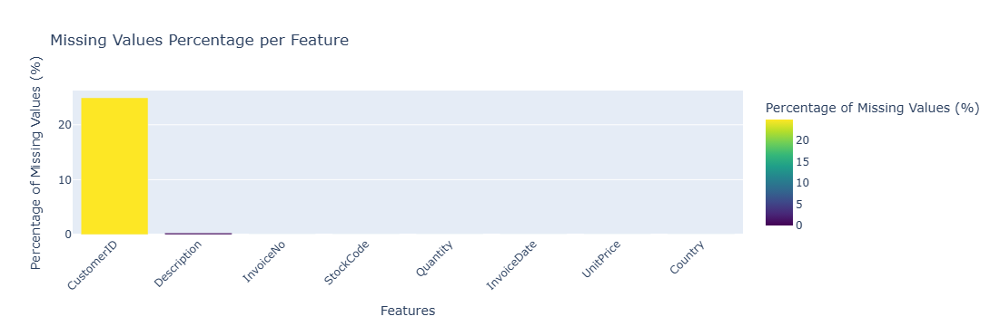

In [13]:
# missing values in train dataset
missing_values = data.isnull().sum()
missing_percentage = data.isnull().sum() * 100 / len(data)
missing_data = pd.DataFrame({'missing_sum': missing_values, 'missing_percentage': missing_percentage})

fig = px.bar(missing_data.sort_values('missing_percentage', ascending=False), 
             x=missing_data.sort_values('missing_percentage', ascending=False).index,
             y='missing_percentage',
             title='Missing Values Percentage per Feature',
             labels={'index': 'Features', 'missing_percentage': 'Percentage of Missing Values (%)'},
             color='missing_percentage',
             color_continuous_scale='Viridis')


fig.update_layout(xaxis_tickangle=-45, 
                  xaxis_title='Features', 
                  yaxis_title='Percentage of Missing Values (%)')


fig.show()


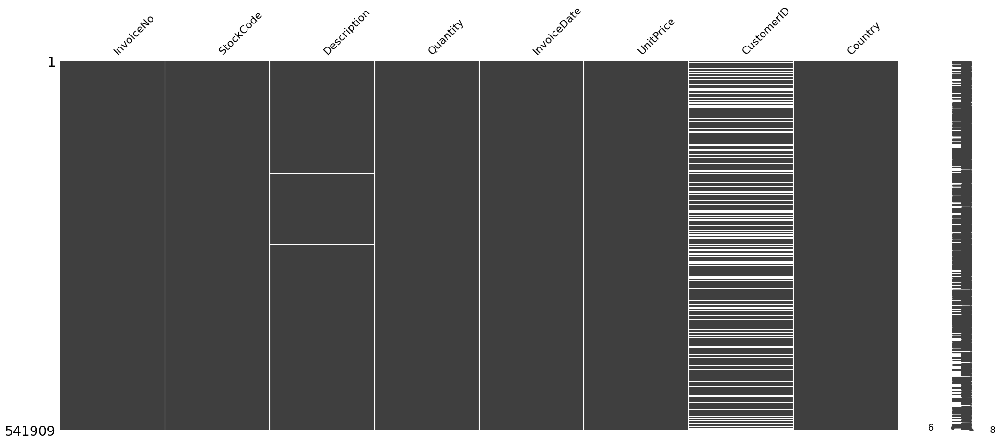

In [14]:
# A visualization that shows the presence= white and absence =black of missing values
msno.matrix(data)
plt.show()

> 🕵️ **Remark:**  
> Columns Description and CustomerID have missing values.


## Distribution of Quantity


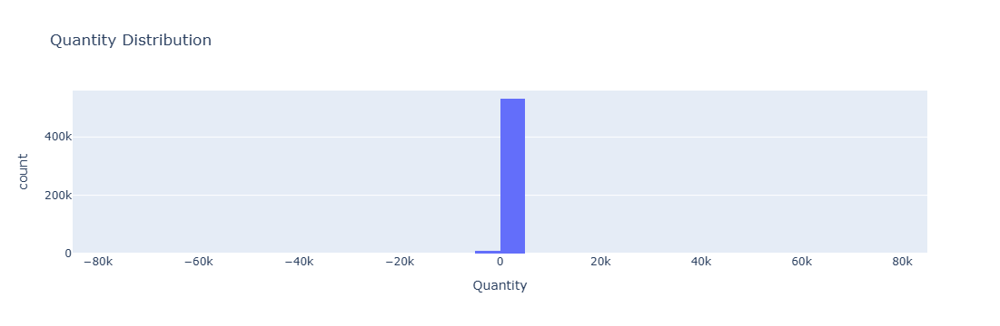

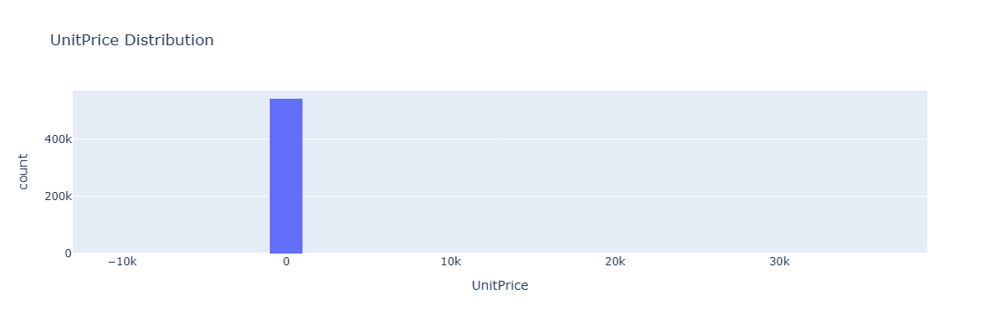

In [18]:
fig = px.histogram(data, x='Quantity', nbins=50, title='Quantity Distribution')
fig.show()


fig = px.histogram(data, x='UnitPrice', nbins=50, title='UnitPrice Distribution')
fig.show()


## Number of invoices per country

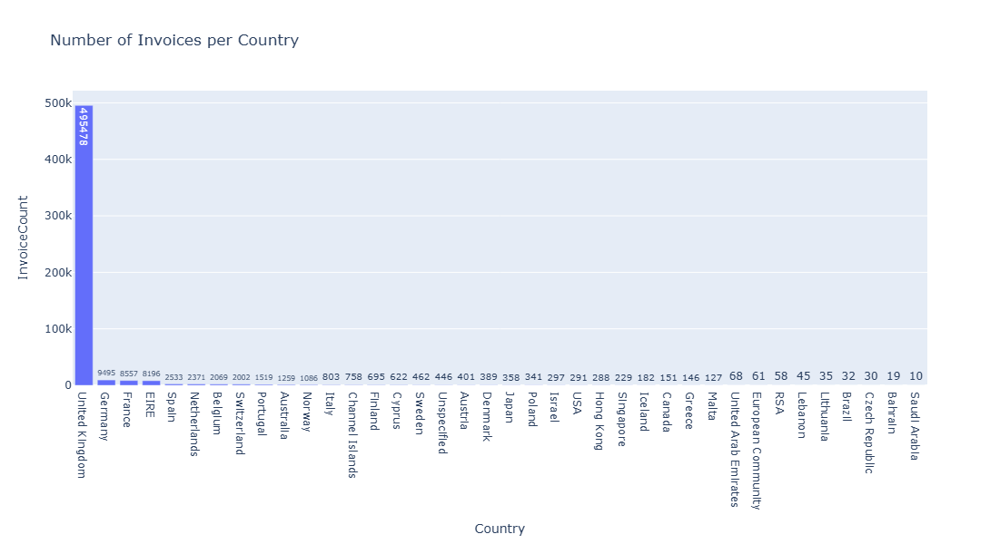

In [30]:
country_counts = data['Country'].value_counts().reset_index()
country_counts.columns = ['Country', 'InvoiceCount']

fig = px.bar(country_counts, x='Country', y='InvoiceCount',
             text='InvoiceCount', title="Number of Invoices per Country",width=1000,  
    height=600 )
fig.show()

## Top 20 most sold products


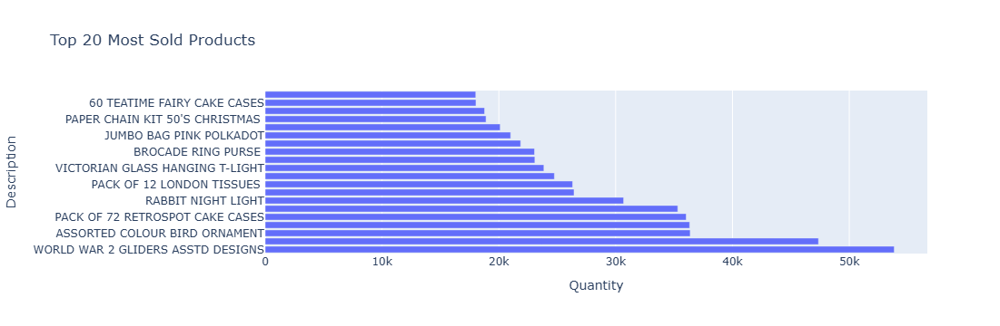

In [22]:
top_products = data.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(20).reset_index()
fig = px.bar(top_products, x='Quantity', y='Description', orientation='h',
             title="Top 20 Most Sold Products")
fig.show()

## Sales over time

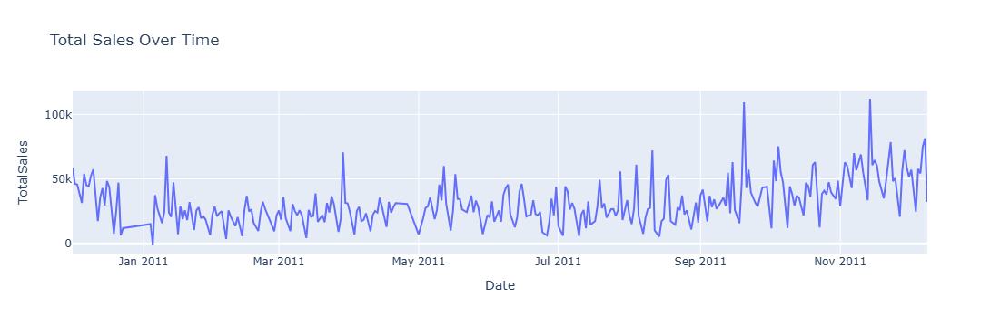

In [23]:
data['InvoiceDate'] = pd.to_datetime(data['InvoiceDate'])

data['TotalPrice'] = data['Quantity'] * data['UnitPrice']
sales_time = data.groupby(data['InvoiceDate'].dt.date)['TotalPrice'].sum().reset_index()
sales_time.columns = ['Date', 'TotalSales']

fig = px.line(sales_time, x='Date', y='TotalSales', title='Total Sales Over Time')
fig.show()

> 🕵️ **Remark:**  
> The sales show a noticeable **peak between September and November 2011**.  
> This suggests a possible **seasonal effect** — perhaps increased demand before the holiday season or a marketing campaign during that period.


## Hourly Purchase Behavior

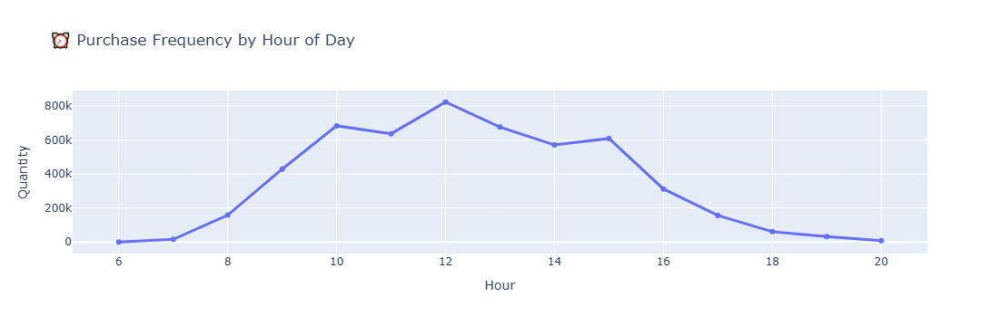

In [36]:
data['Hour'] = data['InvoiceDate'].dt.hour
hourly_sales = data.groupby('Hour')['Quantity'].sum().reset_index()

fig = px.line(hourly_sales, x='Hour', y='Quantity', markers=True,
              title="⏰ Purchase Frequency by Hour of Day")
fig.update_traces(line=dict(width=3))
fig.show()


> 🕵️ **Remark:**  
> The sales have a noticeable **peak at 10 am ,12 pm and 3pm**.  



## Top 15 Customers by Spending

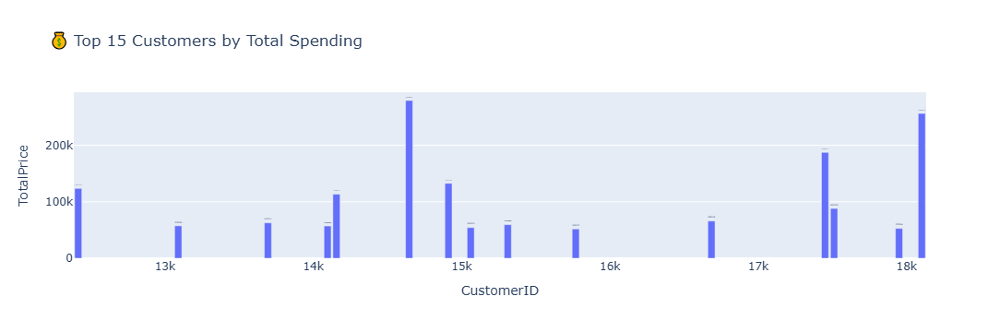

In [38]:
customer_sales = data.groupby('CustomerID')['TotalPrice'].sum().sort_values(ascending=False).head(15).reset_index()

fig = px.bar(customer_sales, x='CustomerID', y='TotalPrice', text='TotalPrice',
             title="💰 Top 15 Customers by Total Spending")
fig.update_traces(textposition='outside')
fig.show()


## Canceled vs Completed Invoices

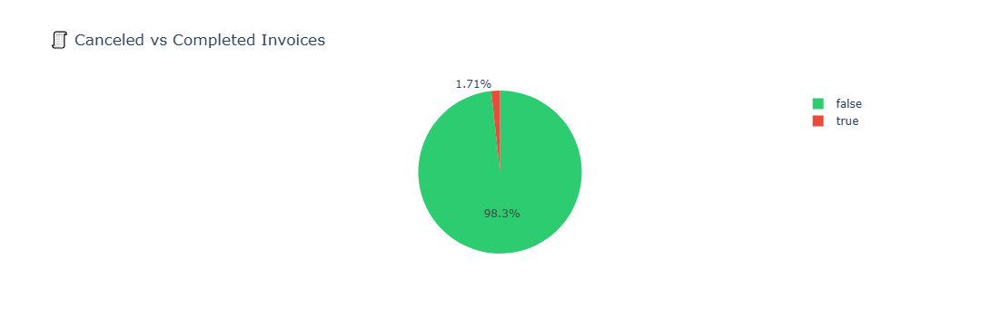

In [41]:
data['Cancelled'] = data['InvoiceNo'].str.startswith('C')
cancel_summary = data['Cancelled'].value_counts().reset_index()
cancel_summary.columns = ['Cancelled', 'Count']

fig = px.pie(cancel_summary, names='Cancelled', values='Count',
             title="🧾 Canceled vs Completed Invoices",
             color_discrete_sequence=['#2ecc71', '#e74c3c'])
fig.show()


## Customers per country

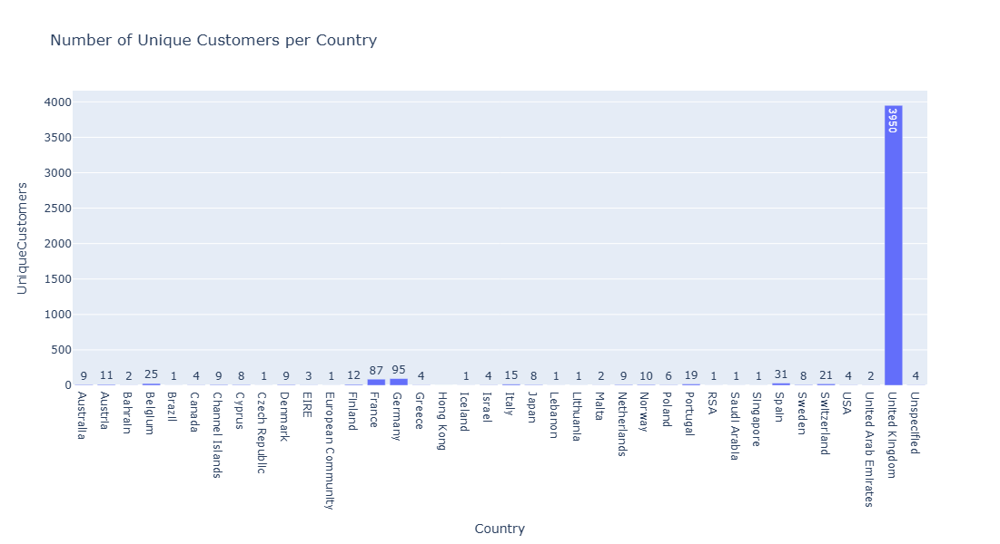

In [31]:
customer_country = data.groupby('Country')['CustomerID'].nunique().reset_index()
customer_country.columns = ['Country', 'UniqueCustomers']

fig = px.bar(customer_country, x='Country', y='UniqueCustomers', text='UniqueCustomers',
             title="Number of Unique Customers per Country",width=1000,   
    height=600 )
fig.show()

## Numbers of orders per country

In [4]:
temp = data[['CustomerID', 'InvoiceNo', 'Country']].groupby(['CustomerID', 'InvoiceNo', 'Country']).count()
temp = temp.reset_index(drop = False)
countries = temp['Country'].value_counts()
print('Number of countries in the dataframe: {}'.format(len(countries)))

Number of countries in the dataframe: 37


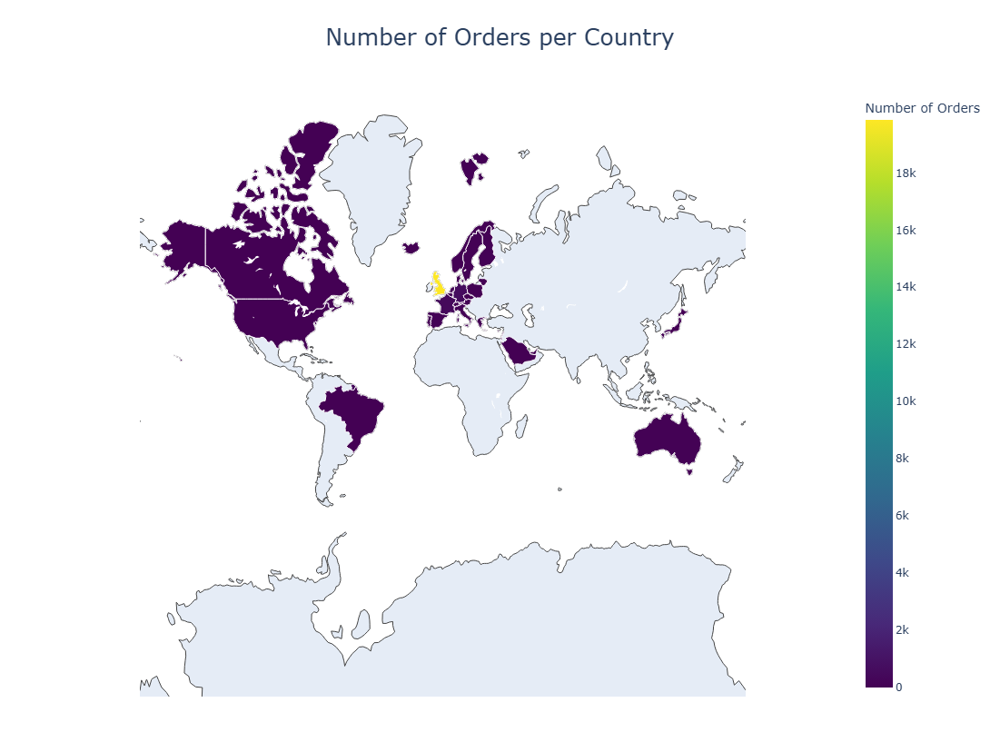

In [7]:


data = go.Choropleth(
    locations=countries.index,
    locationmode='country names',
    z=countries,
    text=countries.index,
    colorscale='Viridis',  
    colorbar=dict(title='Number of Orders'),
    reversescale=False,
    marker_line_color='white',  
    hovertemplate='<b>%{text}</b><br>Orders: %{z}<extra></extra>'
)

layout = go.Layout(
    title=dict(text='Number of Orders per Country', x=0.5, font=dict(size=25)),
    geo=dict(
        showframe=False,
        showcoastlines=True,
        projection_type='mercator'
    ),
    width=1200,   
    height=800,   
    margin=dict(l=50, r=50, t=100, b=50)
)


fig = go.Figure(data=[data], layout=layout)

fig.show()


## Most Preferred Article per Country

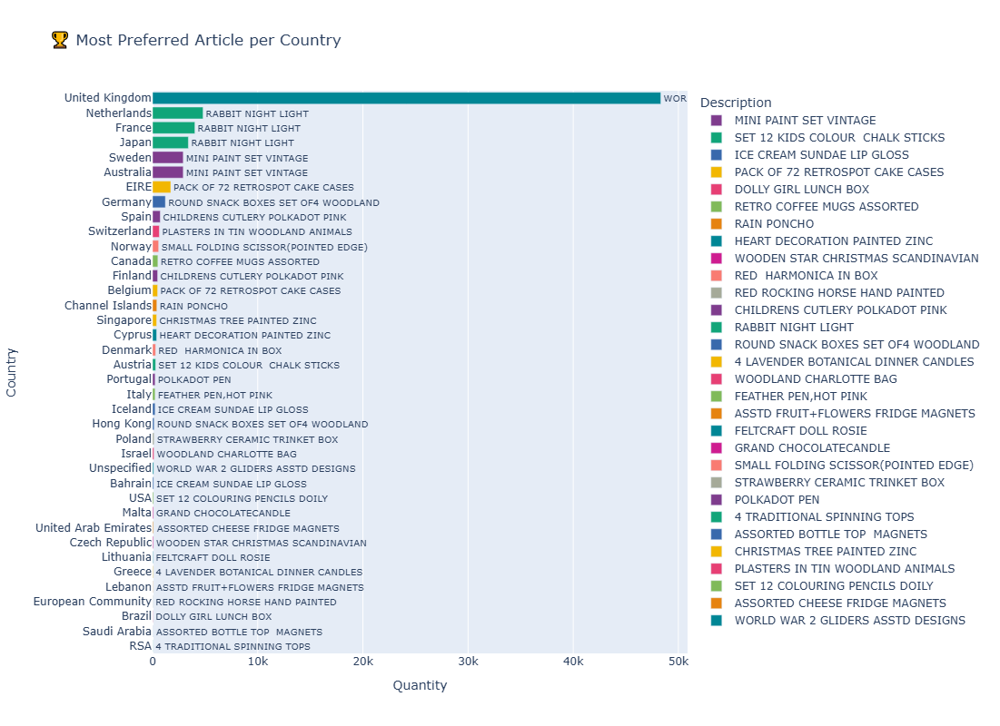

In [42]:
country_product_sales = (
    data.groupby(['Country', 'Description'])['Quantity']
    .sum()
    .reset_index()
)

top_products_by_country = (
    country_product_sales.sort_values(['Country', 'Quantity'], ascending=[True, False])
    .groupby('Country')
    .head(1)
)

fig = px.bar(top_products_by_country,
             x='Quantity',
             y='Country',
             color='Description',
             orientation='h',
             text='Description',
             title="🏆 Most Preferred Article per Country",
             hover_data=['Description', 'Quantity'],
             color_discrete_sequence=px.colors.qualitative.Bold)

fig.update_traces(textposition='outside')
fig.update_layout(height=800, yaxis={'categoryorder': 'total ascending'})
fig.show()


## Cohort Analysis (Customer Retention)

In [5]:
data['InvoiceDate'] = pd.to_datetime(data['InvoiceDate'])
data['InvoiceMonth'] = data['InvoiceDate'].values.astype('datetime64[M]')

cohort = data.groupby('CustomerID')['InvoiceMonth'].min().reset_index()
cohort.columns = ['CustomerID','CohortMonth']
data = pd.merge(data, cohort, on='CustomerID')

def get_month_diff(end, start):
    return (end.year - start.year) * 12 + (end.month - start.month)

data['CohortIndex'] = data.apply(lambda row: get_month_diff(row['InvoiceMonth'], row['CohortMonth']), axis=1)


cohort_data = data.groupby(['CohortMonth','CohortIndex'])['CustomerID'].nunique().reset_index()
cohort_pivot = cohort_data.pivot(index='CohortMonth', columns='CohortIndex', values='CustomerID')


cohort_size = cohort_pivot.iloc[:,0]  # first month size
retention = cohort_pivot.divide(cohort_size, axis=0)



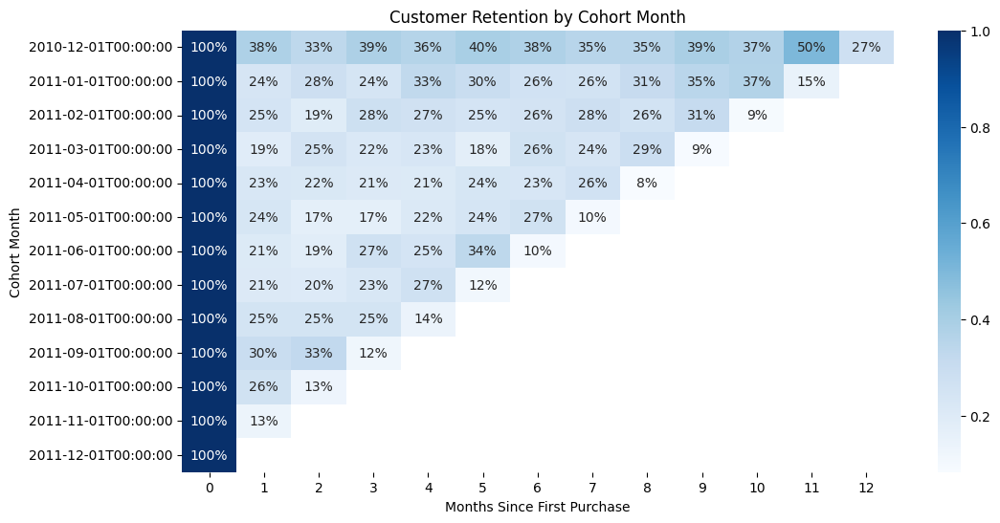

In [6]:
plt.figure(figsize=(12,6))
sns.heatmap(retention, cmap='Blues', annot=True, fmt=".0%")
plt.title("Customer Retention by Cohort Month")
plt.ylabel("Cohort Month")
plt.xlabel("Months Since First Purchase")
plt.show()

**Remark:** High customer churn observed: retention drops significantly after 3–4 months from the first purchase.


##  Correlation heatmap (Quantity vs UnitPrice)

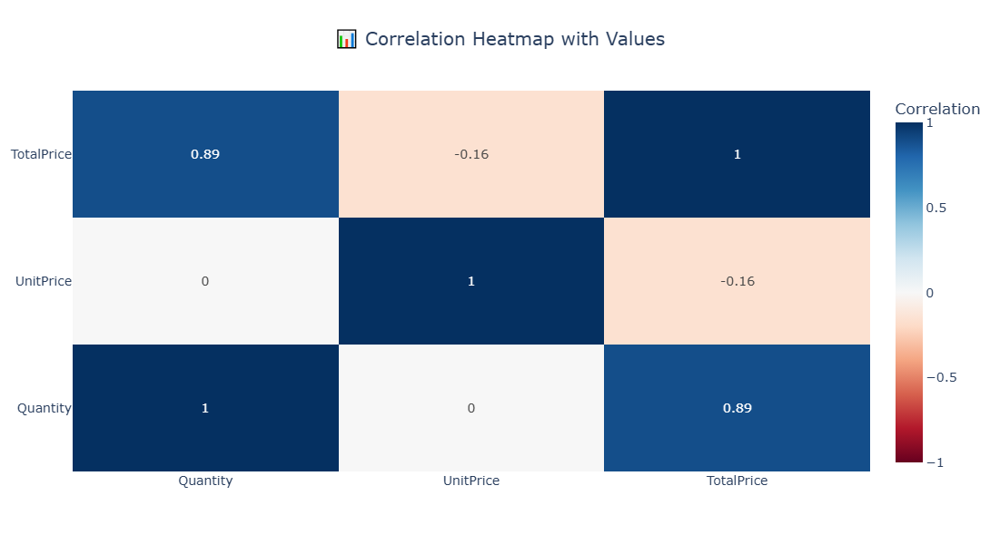

In [34]:
corr_matrix = data[['Quantity', 'UnitPrice', 'TotalPrice']].corr().round(2)

fig = go.Figure(data=go.Heatmap(
    z=corr_matrix.values,
    x=corr_matrix.columns,
    y=corr_matrix.columns,
    colorscale='RdBu',
    zmin=-1,
    zmax=1,
    text=corr_matrix.values,
    texttemplate='%{text}',  
    textfont={"size":14},
    colorbar=dict(title='Correlation')
))

fig.update_layout(
    title='📊 Correlation Heatmap with Values',
    title_x=0.5,
    width=700,
    height=600,
    font=dict(size=14),
    plot_bgcolor='white'
)

fig.show()

> 🧠 **Remark:**  
> The correlation analysis reveals that **TotalPrice** has a **strong positive relationship (0.88)** with **Quantity**, meaning total sales are primarily driven by the **number of items sold**.  
> In contrast, **UnitPrice** shows a **weak negative correlation (-0.16)** with **TotalPrice**, suggesting that **higher prices slightly reduce total sales**, possibly because customers buy fewer units of expensive items.  
>  
> 💡 **Deduction:**  
> The business’s revenue growth depends more on **increasing sales volume** rather than raising prices. Strategic efforts should therefore focus on **boosting quantity sold** not expensive items — through promotions, bundles, or customer incentives.


### 🚨 Detect outliers 

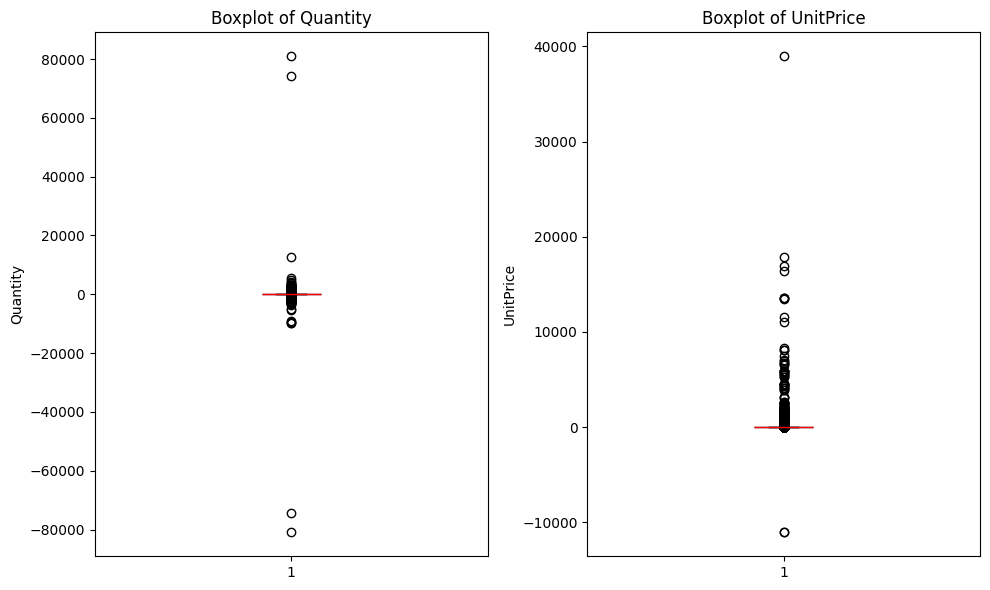

In [16]:
num_cols = data.select_dtypes(include=['int64', 'float64']).columns
num_cols = [col for col in num_cols if col != 'CustomerID']

plt.figure(figsize=(5 * len(num_cols), 6))

for i, col in enumerate(num_cols, 1):
    plt.subplot(1, len(num_cols), i)
    plt.boxplot(data[col], vert=True, patch_artist=True,
                boxprops=dict(facecolor="#1f77b4", color="black"),
                medianprops=dict(color="red"))
    plt.title(f"Boxplot of {col}")
    plt.ylabel(col)

plt.tight_layout()
plt.show()


## 📊 Q-Q plot to see if the data follows a normal distribution

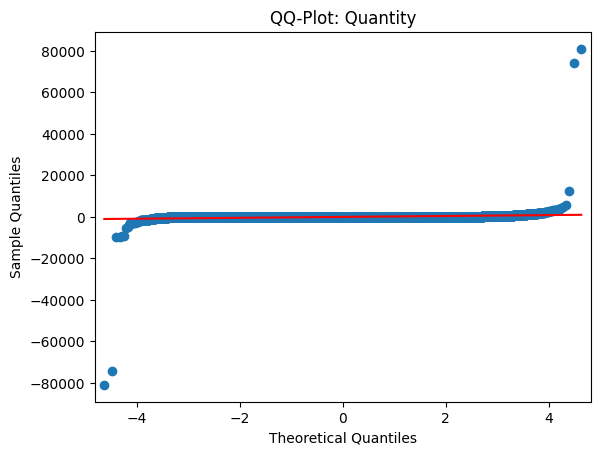

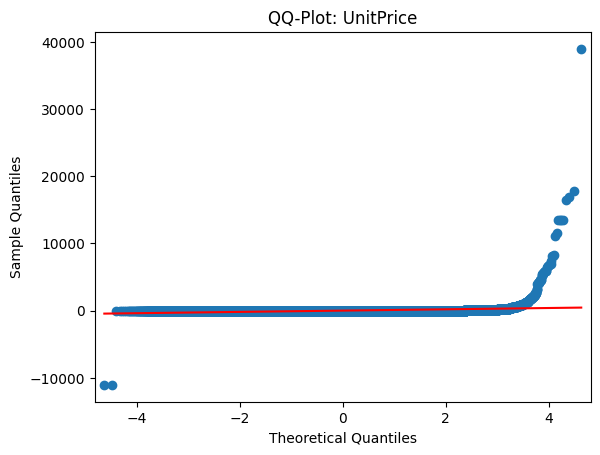

In [8]:
import statsmodels.api as sm
import matplotlib.pyplot as plt

# QQ-plot for Quantity
sm.qqplot(data['Quantity'], line='s')
plt.title("QQ-Plot: Quantity")
plt.show()

# QQ-plot for UnitPrice
sm.qqplot(data['UnitPrice'], line='s')
plt.title("QQ-Plot: UnitPrice")
plt.show()


### 📉 Calculate skewness and kurtosis for each variable

In [10]:
num_cols = data.select_dtypes(include=['int64', 'float64']).columns
num_cols = [col for col in num_cols if col != 'CustomerID']

results = []
for var in num_cols:
    skewness = stats.skew(data[var])
    kurtosis = stats.kurtosis(data[var])
    
    results.append({
        'Feature': var,
        'Skewness': skewness,
        'Kurtosis': kurtosis
    })

results_df = pd.DataFrame(results)

display(results_df)

,Feature,Skewness,Kurtosis
0,Quantity,-0.264076,119768.054955
1,UnitPrice,186.506455,59005.174663


> 🧠 **Remark on Skewness and Kurtosis:**  
> 
> - **Quantity:**  
>   - Skewness = -0.26 → approximately **symmetric**, only a slight left skew.  
>   - Kurtosis = 119,768 → extremely high, indicating the presence of **extreme outliers** in the dataset.  

> 
> - **UnitPrice:**  
>   - Skewness = 186.5 → **highly positively skewed**, meaning most items are low-priced, with a few **very expensive products**.  
>   - Kurtosis = 59,005 → extremely heavy-tailed, confirming the presence of **extreme price outliers**.  

> 
> ⚠️ **Deduction:** Both `Quantity` and `UnitPrice` contain extreme outliers, which may affect analyses like regression or clustering. Consider **capping, transforming, or removing outliers** for modeling purposes.


## 🔬 Bivariate Analysis

### 📈 Scatter plot to detect relationships, trends and anomalies between two numerical variables

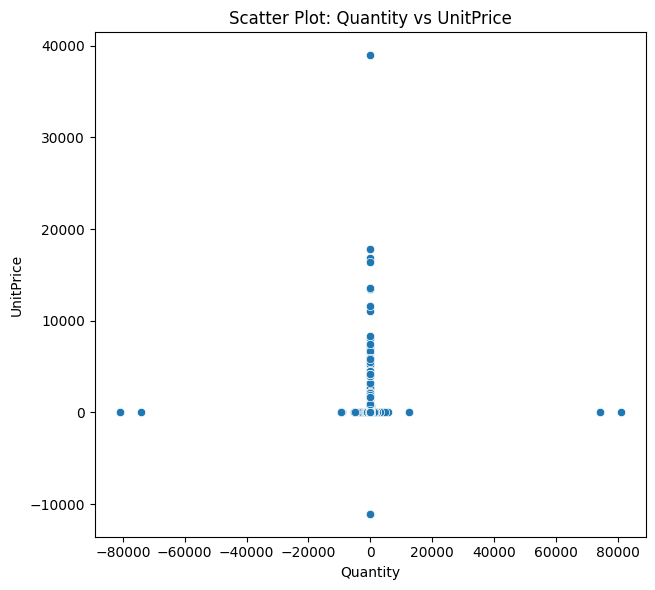

In [11]:
pairs = list(itertools.combinations(num_cols, 2))

fig, axes = plt.subplots(nrows=(len(pairs) // 3) + 1, ncols=3, figsize=(18, 6 * ((len(pairs) // 3) + 1)))
axes = axes.flatten()

for i, (col1, col2) in enumerate(pairs):
    sns.scatterplot(data=data, x=col1, y=col2, ax=axes[i])
    axes[i].set_title(f"Scatter Plot: {col1} vs {col2}")
    axes[i].set_xlabel(col1)
    axes[i].set_ylabel(col2)


for i in range(len(pairs), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

### 🔗 Correlation matrix to see strength and direction of the relationship between variables

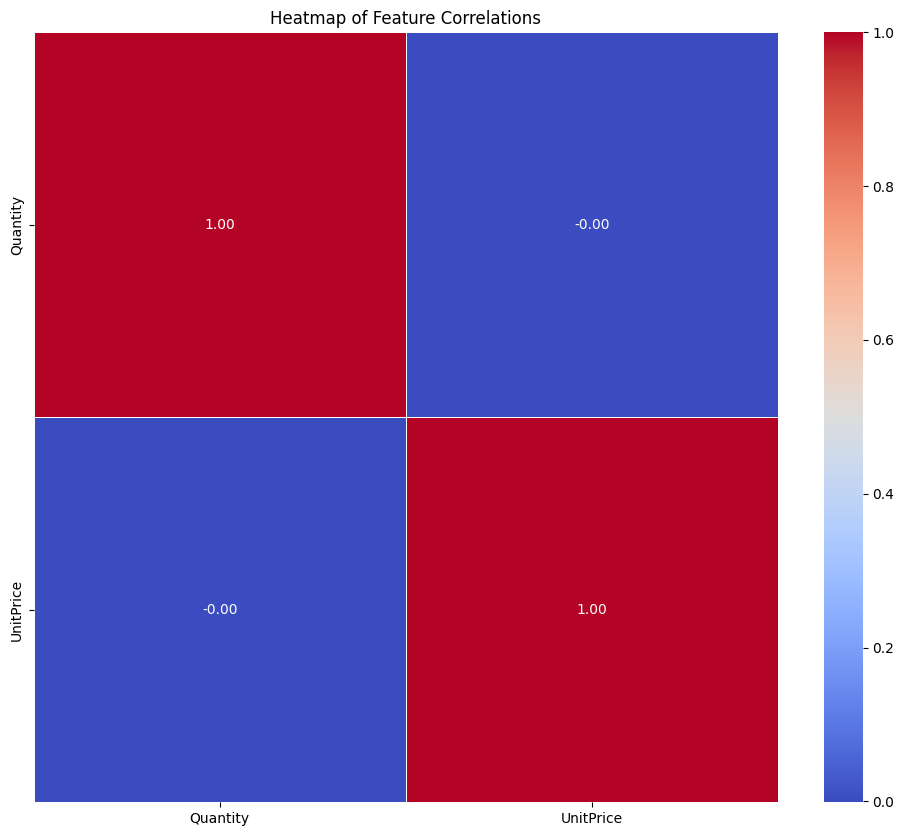

No positive correlations (>|0.9|) found.
No negative correlations (<-0.9) found.


In [13]:
numeric_features = data.select_dtypes(include=['int64', 'float64']).columns.tolist()
numeric_features = [col for col in numeric_features if col not in ['CustomerID']]

corr_matrix = data[numeric_features].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5, annot_kws={"size": 10})
plt.title("Heatmap of Feature Correlations")
plt.show()

positive_corr = []
negative_corr = []

for row in corr_matrix.columns:
    for col in corr_matrix.columns:
        if row != col:
            if corr_matrix.loc[row, col] > 0.9:
                positive_corr.append((row, col, corr_matrix.loc[row, col]))
            elif corr_matrix.loc[row, col] < -0.9:
                negative_corr.append((row, col, corr_matrix.loc[row, col]))

if positive_corr:
    print("These features are positively correlated (>|0.9|):")
    for pair in positive_corr:
        print(f"{pair[0]} and {pair[1]}: {pair[2]:.2f}")
else:
    print("No positive correlations (>|0.9|) found.")

if negative_corr:
    print("\nThese features are negatively correlated (<-0.9):")
    for pair in negative_corr:
        print(f"{pair[0]} and {pair[1]}: {pair[2]:.2f}")
else:
    print("No negative correlations (<-0.9) found.")